# A mechanistic carbon-cycle box model

**Question.** Can a carbon-cycle model built from physical and chemical rules reproduce the CO₂ rise measured at Mauna Loa from historical emissions, without fitting it to the CO₂ record?

**Model.** Four boxes: atmosphere, surface ocean, deep ocean and land. The ocean part is BEAM ([Glotter et al. 2014](https://climate.fas.harvard.edu/sites/projects.iq.harvard.edu/files/climate/files/glotter_etal_2014.pdf)), which computes ocean uptake from carbonate chemistry. The land box adds plant growth that responds to CO₂. The equations are in `box_model.py`.

**Plan.**
1. Check the code: the chemistry matches the paper, and an equilibrium stays put.
2. **Test 1, literature parameters only:** the Joos et al. (2013) pulse test, then the historical run.
3. Find which mechanism causes the misses.
4. **Test 2:** set the two least certain physical rates from *ocean* and *land* data alone, then predict the atmosphere, which is never used to set anything.
5. Limitations.

### In plain words (start here)

- **What this is.** A computer model of where the CO₂ we emit ends up: the air, the ocean or land plants. It's built from physics and chemistry. It is never tuned to the CO₂ measurements, so comparing it with them is a fair test.
- **The three versions** (called Test 1, 2 and 3 below, and Version 1, 2 and 3 on the web page):
    1. Textbook numbers from 1959. The ocean mixes too slowly, so CO₂ comes out 48 ppm too high.
    2. Ocean mixing set from ship measurements of carbon in the ocean. CO₂ is close, but the ocean absorbs too much today.
    3. A middle ocean layer is added. The ocean is right in both the past and the present, and CO₂ is within the uncertainty range.
- **Extras.** Warming feedback (Section 9), uncertainty with 2,000 random runs (Section 10), future scenarios (Section 12), and what happens if emissions stop (Section 13).
- **How to read it.** Each section has a short explanation, then code, then a chart or table. You can skip the code and read the text and charts.

**Words used:** *ppm* is parts per million of CO₂ in air. *GtC* is billion tonnes of carbon (2.124 GtC = 1 ppm). A *sink* is the ocean or land taking CO₂ out of the air. The *thermocline* is the ocean's middle layer, 75–1,000 m deep. *Monte Carlo* means running the model many times with random inputs.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from box_model import Params, params_at, chemistry_at, equilibrium_state, revelle_factor, GTC_PER_PPM
from data_loader import gcb_budget, mauna_loa, noaa_global, observed_co2, ice_core_reconstruction
from experiments import *
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False})
g = gcb_budget()
LIT = Params()
LIT

Params(k_a=0.2, k_d=0.05, delta=50.0, k1=8e-07, k2=4.53e-10, kH=1230.0, AM=1.77e+20, OM=7.8e+22, MUP_ref=713.0, pH_ref=8.29, NPP0=60.0, beta=0.4, tau_L=35.0, land=True)

## 1. Is the code right?

The temperature formulas from the paper (Eqs. 14–16) should reproduce its Table 2. At pH 8.29, the paper's pre-industrial surface ocean (713 GtC) should be in equilibrium with 280 ppm. The automated versions of these checks are in `tests/`.

In [2]:
rows = []
for T, (k1, k2, invA) in {10: (8.00e-7, 4.63e-10, 7.02e-3), 12: (8.30e-7, 4.94e-10, 6.58e-3), 15: (8.75e-7, 5.47e-10, 6.00e-3)}.items():
    c = chemistry_at(T); p = Params(**c)
    rows.append({"T (C)": T, "k1 model": c["k1"], "k1 paper": k1, "k2 model": c["k2"], "k2 paper": k2, "1/A model": 1/p.A, "1/A paper": invA})
display(pd.DataFrame(rows).set_index("T (C)").style.format("{:.3g}"))
s = equilibrium_state(280, LIT)
print(f"Surface ocean in equilibrium with 280 ppm: {s[1]:.1f} GtC (paper: 713). Alkalinity: {LIT.alk:.1f} GtC (paper: 767).")

,k1 model,k1 paper,k2 model,k2 paper,1/A model,1/A paper
T (C),,,,,,
10,7.98e-07,8e-07,4.63e-10,4.63e-10,0.00701,0.00702
12,8.29e-07,8.3e-07,4.94e-10,4.94e-10,0.00657,0.00658
15,8.74e-07,8.75e-07,5.47e-10,5.47e-10,0.00598,0.006


Surface ocean in equilibrium with 280 ppm: 713.0 GtC (paper: 713). Alkalinity: 766.4 GtC (paper: 767).


## 2. Test 1: literature parameters only

### 2a. The Joos et al. (2013) pulse test

Joos et al. ran 15 models with the atmosphere held at 389 ppm and then added 100 GtC. After 1,000 years, **25 ± 9%** was still in the air, **59 ± 12%** in the ocean and **16 ± 14%** on land. The set-up here is the same: the observed CO₂ history up to 2010, then a fixed 389 ppm, then the pulse. The pulse is spread over its first year because BEAM can't take an instant jump.

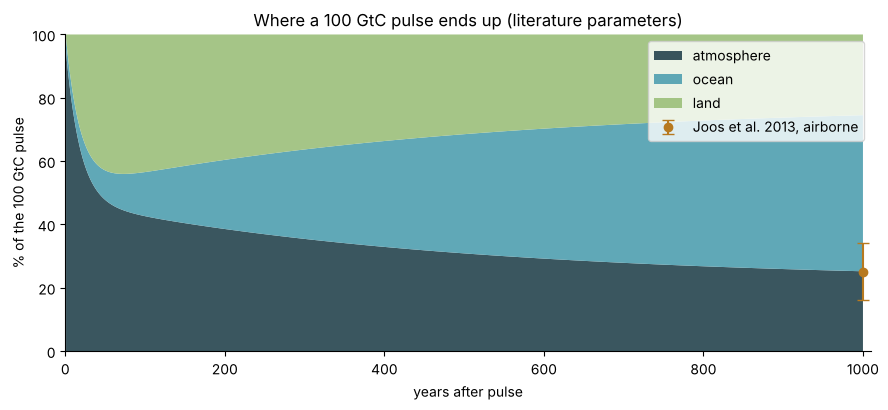

After 1000 yr: atmosphere 25.2% (published 25 ± 9%), ocean 49.3% (59 ± 12%), land 25.5% (16 ± 14%)


In [3]:
pl = pulse_test(LIT)
t = np.arange(1, 1001)
fig, ax = plt.subplots()
ax.stackplot(t, pl["atm"]*100, pl["ocean"]*100, pl["land"]*100, labels=["atmosphere", "ocean", "land"],
             colors=["#24434d", "#4f9fb0", "#9bbf7a"], alpha=.9)
for y, (c, u), col in [(25, JOOS_ATM_1000, "k")]:
    ax.errorbar([1000], [c*100], yerr=[u*100], fmt="o", color="#b7791f", capsize=4, label="Joos et al. 2013, airborne")
ax.set(xlabel="years after pulse", ylabel="% of the 100 GtC pulse", xlim=(0, 1010), ylim=(0, 100),
       title="Where a 100 GtC pulse ends up (literature parameters)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()
print(f"After 1000 yr: atmosphere {pl['atm'][-1]:.1%} (published 25 ± 9%), ocean {pl['ocean'][-1]:.1%} (59 ± 12%), land {pl['land'][-1]:.1%} (16 ± 14%)")

### 2b. Historical run, 1850–2024

The model is driven by Global Carbon Budget 2025 emissions: fossil fuel minus cement carbonation, plus land-use change. It starts in equilibrium at the 1850 ice-core value. The atmosphere is predicted, not prescribed.

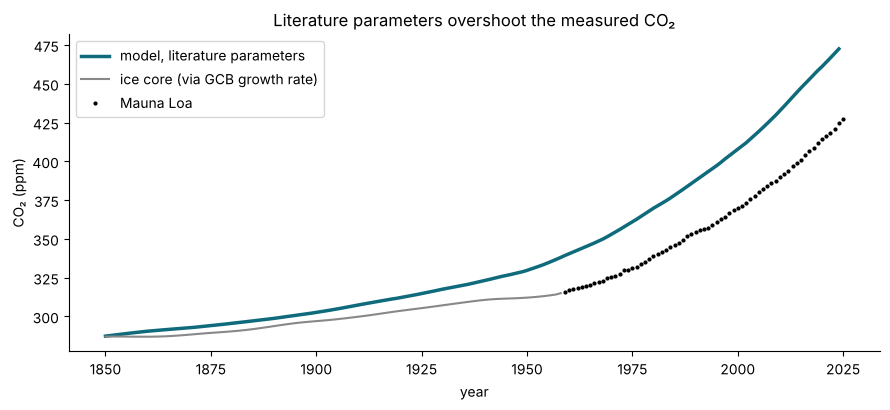

2024: model 472.5 ppm, Mauna Loa 424.6 ppm


In [4]:
lit = scorecard(LIT, "literature")
r = lit["run"]; yrs = r["years"]
obs = observed_co2(); mlo = mauna_loa(); gl = noaa_global()
fig, ax = plt.subplots()
ax.plot(yrs, r["ppm"], lw=2.5, color="#0f6b7c", label="model, literature parameters")
ax.plot(obs.loc[:1958].index, obs.loc[:1958].values, color="#888", lw=1.5, label="ice core (via GCB growth rate)")
ax.plot(mlo.index, mlo.values, "k.", ms=4, label="Mauna Loa")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", title="Literature parameters overshoot the measured CO₂")
ax.legend(); plt.tight_layout(); plt.show()
print(f"2024: model {lit['ppm_2024']:.1f} ppm, Mauna Loa {lit['mlo_2024']:.1f} ppm")

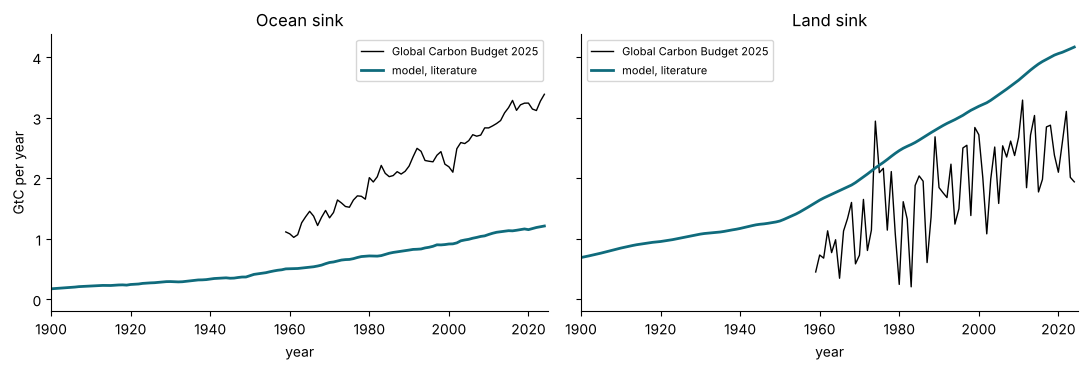

2015-2024 ocean: model 1.17 vs GCB 3.22 ± 0.4 GtC/yr
2015-2024 land:  model 4.04 vs GCB 2.36 ± 0.8 GtC/yr


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, name in [(axs[0], "ocean_sink", "Ocean sink"), (axs[1], "land_sink", "Land sink")]:
    ax.plot(g.loc[1959:2024].index, g.loc[1959:2024, key], color="k", lw=1, label="Global Carbon Budget 2025")
    ax.plot(yrs, r[key], color="#0f6b7c", lw=2, label="model, literature")
    ax.set(title=name, xlabel="year", xlim=(1900, 2025)); ax.legend(fontsize=8)
axs[0].set_ylabel("GtC per year"); plt.tight_layout(); plt.show()
print(f"2015-2024 ocean: model {lit['ocean_sink_2015_2024']:.2f} vs GCB {lit['gcb_ocean_2015_2024']:.2f} ± 0.4 GtC/yr")
print(f"2015-2024 land:  model {lit['land_sink_2015_2024']:.2f} vs GCB {lit['gcb_land_2015_2024']:.2f} ± 0.8 GtC/yr")

**Result of Test 1.** The pulse test passes, but the historical run overshoots by about 48 ppm. The sink panels show why: the model's ocean takes up about a third of what the Global Carbon Budget measures. Because the model is built from mechanisms, the next step is to find which one is responsible.

## 3. Which mechanism limits ocean uptake?

To look at the ocean on its own, the atmosphere is set to the measured CO₂, a concentration-driven run. Each candidate is changed one at a time:

- **k_a**, air–sea gas exchange
- **ocean chemistry**, re-evaluated at warmer surface temperatures with the paper's own formulas
- **k_d**, mixing between the surface and deep ocean

The output is the ocean's total uptake by 1994. [Sabine et al. (2004)](https://oceanfdn.org/sites/default/files/Sabine%20et%20al.%20-%20The%20Oceanic%20Sink%20for%20Anthropogenic%20CO2.pdf) measured it at 118 ± 19 GtC from global ship surveys.

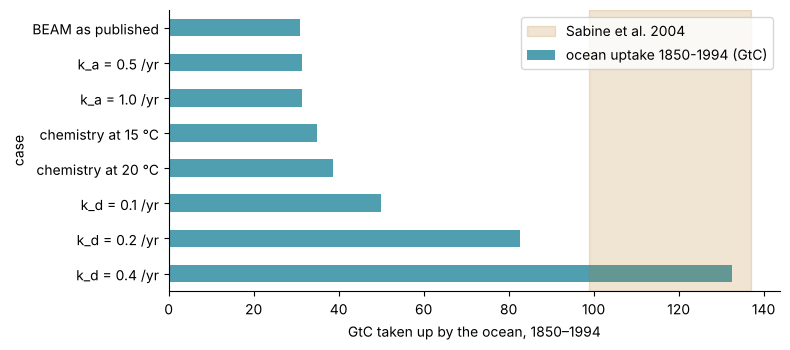

,ocean uptake 1850-1994 (GtC)
case,
BEAM as published,31.0
k_a = 0.5 /yr,31.3
k_a = 1.0 /yr,31.5
chemistry at 15 °C,35.0
chemistry at 20 °C,38.6
k_d = 0.1 /yr,49.9
k_d = 0.2 /yr,82.7
k_d = 0.4 /yr,132.7


In [6]:
cases = [("BEAM as published", LIT)] + \
        [(f"k_a = {v} /yr", Params(k_a=v)) for v in (0.5, 1.0)] + \
        [(f"chemistry at {T} °C", params_at(T)) for T in (15, 20)] + \
        [(f"k_d = {v} /yr", Params(k_d=v)) for v in (0.1, 0.2, 0.4)]
sens = pd.DataFrame([{"case": n, "ocean uptake 1850-1994 (GtC)": ocean_inventory_1994(p)} for n, p in cases]).set_index("case")
ax = sens.plot.barh(legend=False, color="#4f9fb0", figsize=(8, 3.6))
ax.axvspan(SABINE_1994[0]-SABINE_1994[1], SABINE_1994[0]+SABINE_1994[1], color="#b7791f", alpha=.2, label="Sabine et al. 2004")
ax.invert_yaxis(); ax.set_xlabel("GtC taken up by the ocean, 1850–1994"); ax.legend(); plt.tight_layout(); plt.show()
sens.round(1)

**Diagnosis.** Faster gas exchange makes almost no difference: the surface ocean already keeps up with the air. Warmer chemistry helps a little. **Mixing into the deep ocean (k_d) controls the uptake.** The surface box fills quickly and then waits for the deep ocean to take its carbon away.

BEAM's k_d = 0.05 per year (a 20-year exchange time) dates from Bolin & Eriksson (1959), before the tracer surveys that measured how fast the upper ocean actually ventilates. So the main error is a known weak point of the 1959 parameters, not the model's chemistry or structure.

## 4. Test 2: set k_d from ocean data and β from land data, then predict CO₂

The two least certain rates are now set from **reservoir** data. The atmospheric CO₂ record is still never used.

| Rate | Set from | Run type |
|---|---|---|
| k_d (deep mixing) | Ocean uptake by 1994 = 118 GtC (Sabine et al. 2004) | Atmosphere prescribed |
| β (plant fertilization) | Land sink 1960–1999 (GCB 2025) | Atmosphere prescribed |

Everything else is then a prediction: the atmosphere from 1850 to 2024, the ocean and land sinks from 2015 to 2024, the pulse test and its ocean/land split, and the pH decline.

In [7]:
kd = constrain_kd(); kd_lo, kd_hi = constrain_kd(SABINE_1994[0]-SABINE_1994[1]), constrain_kd(SABINE_1994[0]+SABINE_1994[1])
beta = constrain_beta()
print(f"k_d = {kd:.3f} per year (range {kd_lo:.2f}-{kd_hi:.2f} from the ±19 GtC uncertainty); exchange time {1/kd:.1f} yr instead of 20 yr")
print(f"beta = {beta:.3f} (literature range 0.38-0.4, Enting et al. 1994)")
CON = Params(k_d=kd, beta=beta)
con = scorecard(CON, "constrained")

k_d = 0.334 per year (range 0.26-0.42 from the ±19 GtC uncertainty); exchange time 3.0 yr instead of 20 yr
beta = 0.345 (literature range 0.38-0.4, Enting et al. 1994)


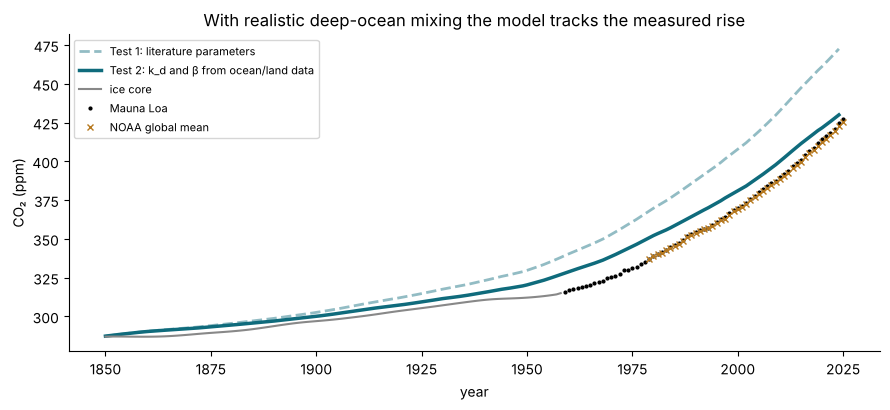

2024: model 430.0 ppm vs Mauna Loa 424.6 ppm


In [8]:
fig, ax = plt.subplots()
rc = con["run"]
ax.plot(yrs, r["ppm"], lw=2, color="#0f6b7c", alpha=.45, ls="--", label="Test 1: literature parameters")
ax.plot(yrs, rc["ppm"], lw=2.5, color="#0f6b7c", label="Test 2: k_d and β from ocean/land data")
ax.plot(obs.loc[:1958].index, obs.loc[:1958].values, color="#888", lw=1.5, label="ice core")
ax.plot(mlo.index, mlo.values, "k.", ms=4, label="Mauna Loa")
ax.plot(gl.index, gl.values, "x", color="#b7791f", ms=4, label="NOAA global mean")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", title="With realistic deep-ocean mixing the model tracks the measured rise")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"2024: model {con['ppm_2024']:.1f} ppm vs Mauna Loa {con['mlo_2024']:.1f} ppm")

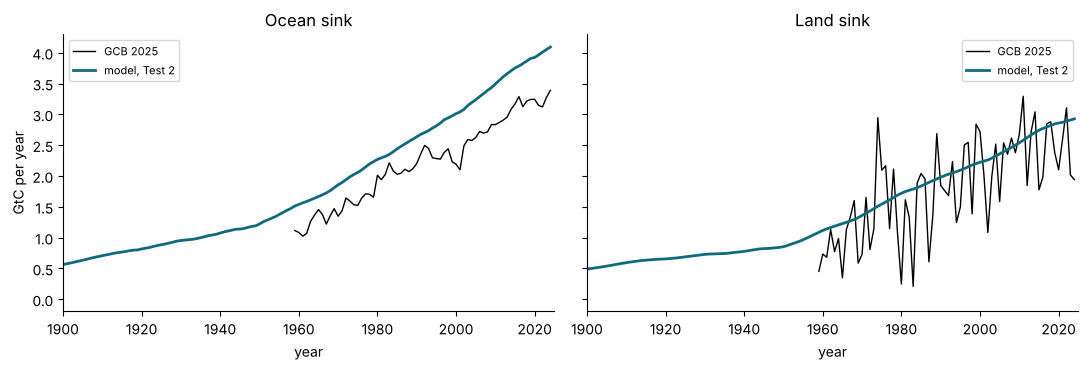

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, name in [(axs[0], "ocean_sink", "Ocean sink"), (axs[1], "land_sink", "Land sink")]:
    ax.plot(g.loc[1959:2024].index, g.loc[1959:2024, key], color="k", lw=1, label="GCB 2025")
    ax.plot(yrs, rc[key], color="#0f6b7c", lw=2, label="model, Test 2")
    ax.set(title=name, xlabel="year", xlim=(1900, 2025)); ax.legend(fontsize=8)
axs[0].set_ylabel("GtC per year"); plt.tight_layout(); plt.show()

## 5. Scorecard

Rows marked *used to set* were used to choose a rate in Test 2, so they don't count as tests there. Everything else is a prediction.

In [10]:
def row(name, pub, unc, key, fmt="{:.2f}", used=False):
    out = {"check": name, "published": (f"{pub} ± {unc}" if unc is not None else str(pub)) if pub is not None else "-"}
    for res in (lit, con):
        v = res[key]
        ok = "" if unc is None else (" ✓" if abs(v - pub) <= unc else " ✗")
        out[res["label"]] = fmt.format(v) + ok
    if used: out["constrained"] += " (used to set)"
    return out
card = pd.DataFrame([
    row("Pulse: airborne after 1000 yr", .25, .09, "pulse_atm_1000"),
    row("Pulse: ocean share after 1000 yr", .59, .12, "pulse_ocean_1000"),
    row("Pulse: land share after 1000 yr", .16, .14, "pulse_land_1000"),
    row("Ocean sink 2015-2024 (GtC/yr)", 3.22, .4, "ocean_sink_2015_2024"),
    row("Land sink 2015-2024 (GtC/yr)", 2.36, .8, "land_sink_2015_2024"),
    row("Surface pH drop 1850-2000", .11, .03, "ph_drop_1850_2000", "{:.3f}"),
    row("CO2 in 2024 (ppm)", 424.6, None, "ppm_2024", "{:.1f}"),
    row("RMSE vs Mauna Loa (ppm)", None, None, "rmse_mlo", "{:.1f}"),
    row("RMSE vs NOAA global mean (ppm)", None, None, "rmse_noaa_global", "{:.1f}"),
    row("RMSE vs ice core 1850-1958 (ppm)", None, None, "rmse_ice_core_1850_1958", "{:.1f}"),
]).set_index("check")
card

,published,literature,constrained
check,,,
Pulse: airborne after 1000 yr,0.25 ± 0.09,0.25 ✓,0.23 ✓
Pulse: ocean share after 1000 yr,0.59 ± 0.12,0.49 ✓,0.57 ✓
Pulse: land share after 1000 yr,0.16 ± 0.14,0.25 ✓,0.20 ✓
Ocean sink 2015-2024 (GtC/yr),3.22 ± 0.4,1.17 ✗,3.92 ✗
Land sink 2015-2024 (GtC/yr),2.36 ± 0.8,4.04 ✗,2.84 ✓
Surface pH drop 1850-2000,0.11 ± 0.03,0.133 ✓,0.101 ✓
CO2 in 2024 (ppm),424.6,472.5,430.0
RMSE vs Mauna Loa (ppm),-,36.2,11.6
RMSE vs NOAA global mean (ppm),-,40.5,11.7


## 6. The Global Carbon Budget itself doesn't close

A model that matched every published sink exactly would still overshoot. The Global Carbon Budget reports a **budget imbalance**: emissions minus everything it can account for. Summed over 1850–2024, that is:

In [11]:
imb = g.loc[1850:2024, "imbalance"].sum()
print(f"Cumulative budget imbalance 1850-2024: {imb:.0f} GtC = {imb/GTC_PER_PPM:.0f} ppm")
print(f"  of which before 1959: {g.loc[1850:1958,'imbalance'].sum()/GTC_PER_PPM:.0f} ppm")
off = pd.Series(rc["ppm"], index=yrs) - obs.loc[1850:2024]
print(f"Test 2 model minus observed: 1959 {off[1959]:+.1f} ppm, 2024 {off[2024]:+.1f} ppm")

Cumulative budget imbalance 1850-2024: 80 GtC = 38 ppm
  of which before 1959: 21 ppm
Test 2 model minus observed: 1959 +12.1 ppm, 2024 +5.4 ppm


Most of the model's remaining offset (about +12 ppm) builds up before 1959, when the budget's own imbalance is largest (about 21 ppm). Ice-core CO₂ even levelled off in the 1940s while emissions kept rising. The early land-use emissions are the least certain input, which makes them the most likely cause.

## 7. Limitations of the two-layer model

Sections 8–10 deal with the first item and the last one.

- **Two-layer ocean.** One mixing rate can't match both the 1994 inventory and the recent sink: with k_d set from the inventory, the 2015–2024 sink is about 3.9 GtC/yr against the GCB's 3.2 ± 0.4. A real ocean has a gradual thermocline, not two layers.
- **Ocean chemistry.** The model's Revelle factor in 2000 is about 17. That is high compared with the roughly 11 implied by [Jiang et al. (2019)](https://www.nature.com/articles/s41598-019-55039-4), whose RCP8.5 projection has it rising by 3.7 (about 34%) after 2000. The cause is BEAM's 10 °C constants and fixed alkalinity.
- **Simple land.** A single fertilization factor, with no temperature or nitrogen limits, and an approximate turnover time.
- **No climate feedback.** Warming that reduces ocean and land uptake isn't included.

## 8. Fix 1: a three-layer ocean

The two-layer failure in Section 7 is structural. One mixing rate either fills the ocean fast enough to match the 1994 inventory, or slowly enough to match today's sink, but not both. A real ocean has a **thermocline**, a middle layer down to about 1,000 m that is ventilated within decades, above a deep ocean that turns over in centuries.

Split BEAM's deep box by depth, using a mean ocean depth of about 3,700 m:

| Layer | Depth | Volume (surface units) | Exchange |
|---|---|---|---|
| Surface | 0–75 m | 1 | air–sea, k_a = 0.2 /yr (BEAM) |
| Thermocline | 75–1,000 m | 12.5 | k_1 with the surface |
| Deep | below 1,000 m | 37.5 | k_2 with the thermocline |

**Both rates come from ocean observations, never from the CO₂ record:**

- **k_2** comes from the radiocarbon age of deep water. [Matsumoto (2007)](https://www.whoi.edu/cms/files/Matsumoto_2007_282004.pdf) measured circulation ages below 1,500 m of about 300 years (Atlantic) to 900 years (Pacific). In the model, the deep water's mean age is V_deep / (k_2 V_thermocline) = 3 / k_2. The midpoint of 600 years gives k_2 = 0.005 per year.
- **k_1** comes from the 1994 ocean inventory, as in Test 2.

The test is whether this predicts the 2015–2024 ocean sink, which the two-layer model missed.

In [12]:
from ocean3 import simulate, pulse3
from experiments3 import central_params, summarise, monte_carlo, interval, future_emissions, EF, EL, OBS, START, DEEP_AGE
c3 = central_params()
print(f"k_2 = {c3['k2m']:.4f}/yr from a {c3['deep_age']:.0f}-yr deep-water age; k_1 = {c3['k1m']:.2f}/yr from 118 GtC by 1994; beta = {c3['beta']:.3f}")
kw3 = dict(k1m=c3["k1m"], k2m=c3["k2m"], beta=c3["beta"], start_ppm=START)
r3 = simulate(EF, EL, **kw3)
s3 = summarise(r3)
bg3 = simulate(EF[:161], EL[:161], prescribed=OBS[:161], **kw3)
pl3 = pulse3(bg3["final"], k1m=c3["k1m"], k2m=c3["k2m"], beta=c3["beta"])
cmp = pd.DataFrame({
    "published": ["3.22 ± 0.4", "25 ± 9%", "59 ± 12%", "16 ± 14%", "0.11 ± 0.03", "424.6"],
    "two layers (Test 2)": [f"{con['ocean_sink_2015_2024']:.2f}", f"{con['pulse_atm_1000']:.0%}", f"{con['pulse_ocean_1000']:.0%}",
                            f"{con['pulse_land_1000']:.0%}", f"{con['ph_drop_1850_2000']:.3f}", f"{con['ppm_2024']:.1f}"],
    "three layers": [f"{s3['ocean_2015_2024'].item():.2f}", f"{pl3['atm'][-1]:.0%}", f"{pl3['ocean'][-1]:.0%}",
                     f"{pl3['land'][-1]:.0%}", f"{s3['pH_drop_1850_2000'].item():.3f}", f"{s3['ppm_2024'].item():.1f}"]},
    index=["Ocean sink 2015-2024 (GtC/yr)", "Pulse airborne, 1000 yr", "Pulse in ocean, 1000 yr", "Pulse on land, 1000 yr",
           "Surface pH drop 1850-2000", "CO2 in 2024 (ppm)"])
cmp

k_2 = 0.0050/yr from a 600-yr deep-water age; k_1 = 1.10/yr from 118 GtC by 1994; beta = 0.345


,published,two layers (Test 2),three layers
Ocean sink 2015-2024 (GtC/yr),3.22 ± 0.4,3.92,3.44
"Pulse airborne, 1000 yr",25 ± 9%,23%,24%
"Pulse in ocean, 1000 yr",59 ± 12%,57%,55%
"Pulse on land, 1000 yr",16 ± 14%,20%,21%
Surface pH drop 1850-2000,0.11 ± 0.03,0.101,0.104
CO2 in 2024 (ppm),424.6,430.0,435.3


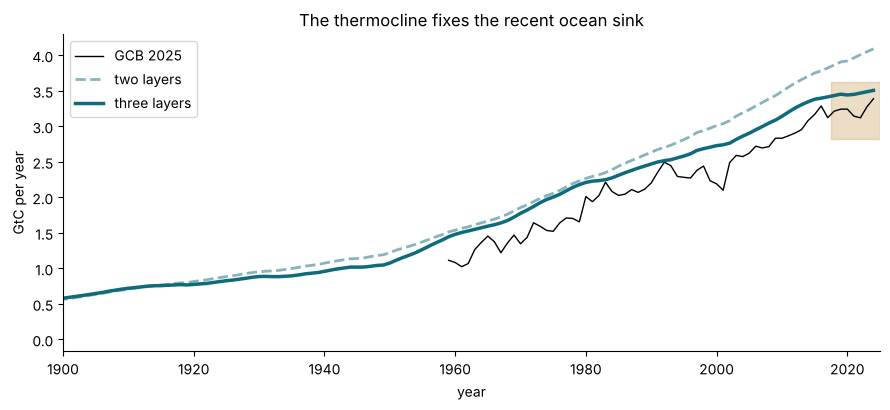

In [13]:
fig, ax = plt.subplots()
ax.plot(g.loc[1959:2024].index, g.loc[1959:2024, "ocean_sink"], color="k", lw=1, label="GCB 2025")
ax.plot(yrs, con["run"]["ocean_sink"], color="#0f6b7c", lw=2, alpha=.5, ls="--", label="two layers")
ax.plot(yrs, r3["ocean"][:, 0], color="#0f6b7c", lw=2.5, label="three layers")
ax.axhspan(3.22 - .4, 3.22 + .4, xmin=0.94, color="#b7791f", alpha=.25)
ax.set(xlabel="year", ylabel="GtC per year", xlim=(1900, 2025), title="The thermocline fixes the recent ocean sink")
ax.legend(); plt.tight_layout(); plt.show()

**Result.** With a thermocline, the ocean now passes both checks: 118 GtC by 1994 (used to set k_1) and the 2015–2024 sink (a prediction, inside 3.22 ± 0.4). The pulse test still passes.

The atmosphere moves the other way, from +5 to about +11 ppm in 2024. The three-layer ocean takes up less in recent decades, which is what the Global Carbon Budget measures. The two-layer model's closer CO₂ match therefore came partly from an ocean that was too strong. The remaining gap is about a third of the GCB's own 38 ppm budget imbalance.

## 9. Fix 2: warming feedback

Warmer water holds less CO₂, and its carbonate chemistry shifts. Warming is computed from cumulative emissions with the IPCC AR6 **TCRE** (transient climate response to cumulative emissions): **1.4–2.2 °C per 1,000 GtC** (likely range), with the midpoint of 1.8 used here. The ocean chemistry constants (k₁, k₂, solubility) are then re-evaluated every time step at 10 °C + ΔT, using the same Glotter et al. formulas tested in Section 1.

Two simplifications are made. The surface ocean warms as much as the global average, which is an upper bound, since sea-surface warming is smaller. And the rates are kept from Section 8, so this measures the size of the feedback alone.

Warming by 2024 from cumulative emissions: 1.34 C (WMO State of the Global Climate 2024: long-term warming 1.34-1.41 C above 1850-1900)
CO2 in 2024: 435.3 ppm without feedback, 442.2 ppm with  (+6.9 ppm)
Ocean sink 2015-2024: 3.44 -> 3.08 GtC/yr


If emissions stay at the 2024 level to 2100: 610 ppm without feedback, 628 ppm with (+18); warming 2.9 C


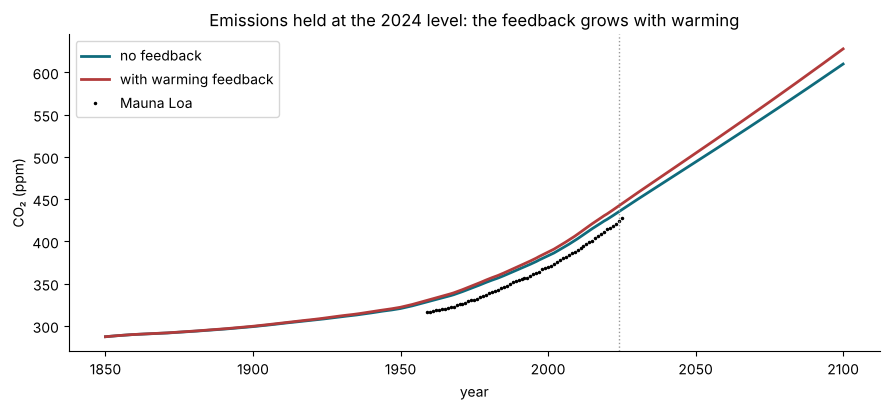

In [14]:
r3f = simulate(EF, EL, feedback=True, **kw3)
s3f = summarise(r3f)
print(f"Warming by 2024 from cumulative emissions: {s3f['dT_2024'].item():.2f} C (WMO State of the Global Climate 2024: long-term warming 1.34-1.41 C above 1850-1900)")
print(f"CO2 in 2024: {s3['ppm_2024'].item():.1f} ppm without feedback, {s3f['ppm_2024'].item():.1f} ppm with  (+{(s3f['ppm_2024']-s3['ppm_2024']).item():.1f} ppm)")
print(f"Ocean sink 2015-2024: {s3['ocean_2015_2024'].item():.2f} -> {s3f['ocean_2015_2024'].item():.2f} GtC/yr")
Ef2, El2, y2 = future_emissions(0.0)
a = simulate(Ef2, El2, **kw3); b = simulate(Ef2, El2, feedback=True, **kw3)
print(f"If emissions stay at the 2024 level to 2100: {a['ppm'][-1].item():.0f} ppm without feedback, {b['ppm'][-1].item():.0f} ppm with (+{(b['ppm'][-1]-a['ppm'][-1]).item():.0f}); warming {b['dT'][-1].item():.1f} C")
fig, ax = plt.subplots()
ax.plot(y2, a["ppm"][:, 0], color="#0f6b7c", lw=2, label="no feedback")
ax.plot(y2, b["ppm"][:, 0], color="#b23b3b", lw=2, label="with warming feedback")
ax.plot(mlo.index, mlo.values, "k.", ms=3, label="Mauna Loa")
ax.axvline(2024, color="#999", lw=1, ls=":")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", title="Emissions held at the 2024 level: the feedback grows with warming"); ax.legend()
plt.tight_layout(); plt.show()

## 10. Uncertainty: Monte Carlo

Every uncertain input is drawn at random from its published range, 2,000 times. Each draw then sets its own rates from *its* ocean and land data, never from the CO₂ record, and runs 1850–2024.

| Input | Distribution | Source |
|---|---|---|
| Land-use emissions | × N(1, 0.5) | GCB 2025: 1.4 ± 0.7 GtC/yr |
| Fossil emissions | × N(1, 0.05) | GCB 2025: 10.3 ± 0.5 GtC/yr |
| Ocean inventory 1994 → k_1 | N(118, 19) GtC | Sabine et al. 2004 |
| Deep-water age → k_2 | uniform 300–900 yr | Matsumoto 2007 |
| Land sink 1960–1999 → β | N(1.47, 0.8) GtC/yr | GCB 2025 land-sink uncertainty |
| TCRE (feedback runs) | uniform 1.4–2.2 °C/1000 GtC | IPCC AR6 |

About 8% of draws ask for more ocean uptake than any k_1 can give, so they use the fully mixed limit, k_1 = 10 per year.

,"CO2 2024, 5%",median,95%,share of runs below 424.6 ppm
runs,,,,
no feedback,387.34,435.72,503.80,0.38
with warming feedback,392.26,442.88,514.42,0.30


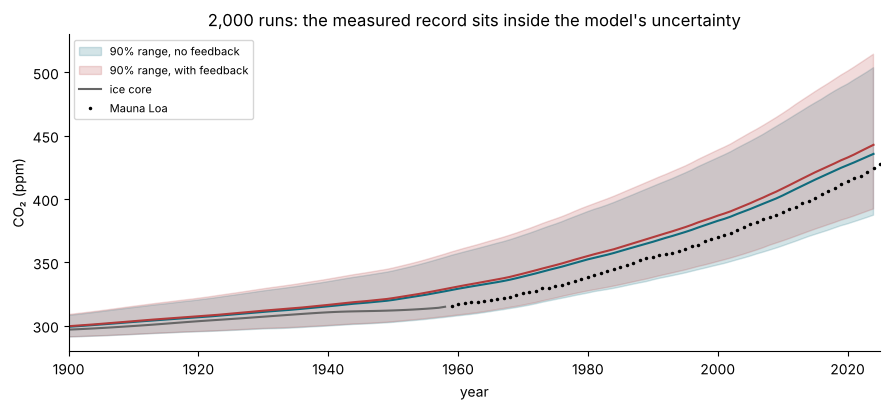

In [15]:
mc, draws = monte_carlo(2000)
mcf, drawsf = monte_carlo(2000, feedback=True)
sm, smf = summarise(mc), summarise(mcf)
rows = []
for name, s in [("no feedback", sm), ("with warming feedback", smf)]:
    lo, mid, hi = interval(s["ppm_2024"])
    rows.append({"runs": name, "CO2 2024, 5%": lo, "median": mid, "95%": hi,
                 "share of runs below 424.6 ppm": (s["ppm_2024"] < 424.61).mean()})
display(pd.DataFrame(rows).set_index("runs").round(2))
fig, ax = plt.subplots()
for runs, col, lab in [(mc, "#0f6b7c", "90% range, no feedback"), (mcf, "#b23b3b", "90% range, with feedback")]:
    ax.fill_between(yrs, np.percentile(runs["ppm"], 5, axis=1), np.percentile(runs["ppm"], 95, axis=1), color=col, alpha=.18, label=lab)
    ax.plot(yrs, np.percentile(runs["ppm"], 50, axis=1), color=col, lw=1.5)
ax.plot(obs.loc[:1958].index, obs.loc[:1958].values, color="#666", lw=1.5, label="ice core")
ax.plot(mlo.index, mlo.values, "k.", ms=3, label="Mauna Loa")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", xlim=(1900, 2025), ylim=(280, 530), title="2,000 runs: the measured record sits inside the model's uncertainty")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

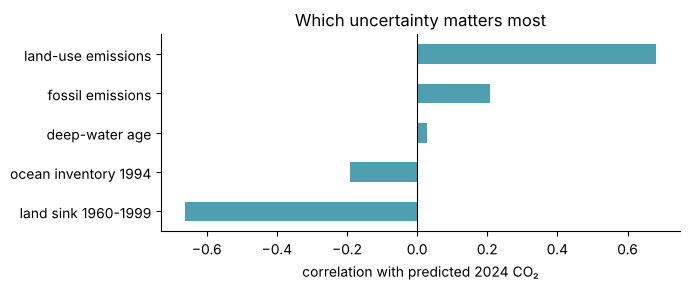

land-use emissions      0.68
land sink 1960-1999    -0.66
fossil emissions        0.21
ocean inventory 1994   -0.19
deep-water age          0.03
dtype: float64

In [16]:
corr = pd.Series({c: np.corrcoef(draws[c], sm["ppm_2024"])[0, 1] for c in
                   ["f_luc", "land_target", "f_fossil", "inventory", "deep_age"]}).rename(
    {"f_luc": "land-use emissions", "land_target": "land sink 1960-1999", "f_fossil": "fossil emissions",
     "inventory": "ocean inventory 1994", "deep_age": "deep-water age"})
ax = corr.sort_values().plot.barh(color="#4f9fb0", figsize=(7, 3)); ax.axvline(0, color="k", lw=.8)
ax.set(xlabel="correlation with predicted 2024 CO₂", title="Which uncertainty matters most"); plt.tight_layout(); plt.show()
corr.round(2)

**Result.** The model's 90% range for 2024 is wide, roughly 390–500 ppm, and the measured 424.6 ppm falls well inside it. Two inputs dominate the spread: **land-use emissions** and the **land sink**. The ocean parameters matter much less.

So the main limit on predicting today's CO₂ from emissions isn't the ocean physics. It's how poorly we know what land clearing emits and what forests absorb. That is the same land uncertainty behind the Global Carbon Budget's own budget imbalance.

## 11. Updated summary

| Question | Answer |
|---|---|
| Does a model built from physics pass the Joos pulse test? | Yes, with two layers or three |
| Can it match both the ocean's long-term inventory and today's sink? | Only with a thermocline, which needs three layers |
| How much does ocean warming feedback add? | About +7 ppm by 2024, and more under continued emissions |
| Is the measured CO₂ consistent with the model, given published uncertainties? | Yes. 424.6 ppm sits at about the 38th percentile of 2,000 runs (30th with the feedback). Land uncertainty sets the range. |

## 12. Future scenarios to 2100

The Test 3 model (three layers, warming feedback on) is run under four emissions paths after 2024. Fossil and land-use emissions follow the same path:

| Scenario | Emissions after 2024 |
|---|---|
| Held flat | Stay at the 2024 level |
| Cut 2% per year | Fall 2% each year (about 21% of today by 2100) |
| Net zero by 2050 | Straight-line decline to zero in 2050, then zero |
| Stop in 2025 | Zero from 2025 |

Each scenario is also run 2,000 times with the Monte Carlo draws from Section 10. **Caveat:** every run starts from the model's own 2024 state, which is about 18 ppm above Mauna Loa with the feedback on. The *differences* between scenarios are more reliable than the absolute values.

,peak CO2 (ppm),peak 90% range,peak year,peak year 90% range,CO2 2050,CO2 2100,CO2 2100 90% range,warming 2100 (C)
scenario,,,,,,,,
Held at the 2024 level,627.9,525-779,2100,2100-2100,504.4,627.9,525-779,2.9
Cut 2% per year,502.9,432-614,2100,2100-2100,480.9,502.9,432-614,2.1
Net zero by 2050 (straight-line decline),458.4,403-543,2039,2036-2044,451.3,430.6,380-512,1.6
Stop all emissions in 2025,442.2,392-514,2024,2024-2024,413.3,402.7,361-470,1.3


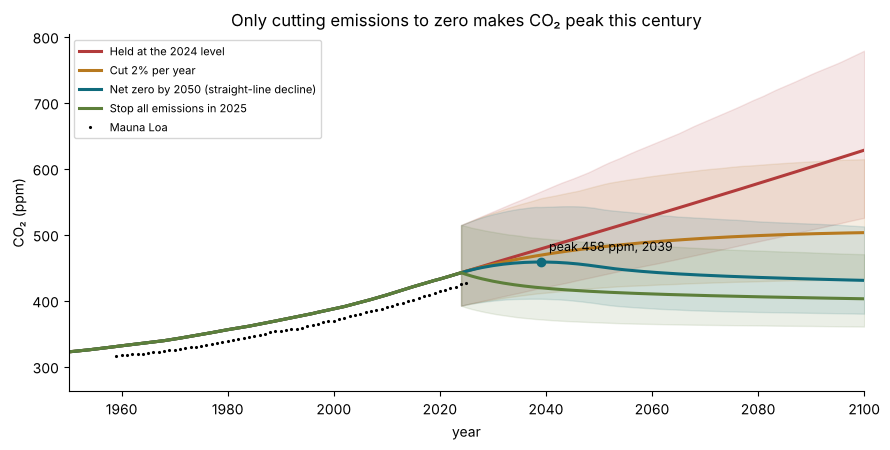

In [17]:
from experiments3 import run_scenarios, scenario_emissions, stop_today, SCENARIOS
table_fb, runs_fb = run_scenarios(2000, feedback=True)
table_nofb, _ = run_scenarios(2000, feedback=False)
display(table_fb.round(1))
fig, ax = plt.subplots(figsize=(9, 4.6))
cols = {"flat": "#b23b3b", "cut2": "#b7791f", "netzero2050": "#0f6b7c", "stop": "#5d7f3a"}
for k, v in runs_fb.items():
    y, mc = v["years"], v["mc"]["ppm"]; m = y >= 2024
    ax.fill_between(y[m], np.percentile(mc, 5, axis=1)[m], np.percentile(mc, 95, axis=1)[m], color=cols[k], alpha=.12)
    ax.plot(y, v["central"]["ppm"][:, 0], color=cols[k], lw=2.2, label=SCENARIOS[k])
    py, pv = y[np.argmax(v["central"]["ppm"][:, 0])], v["central"]["ppm"][:, 0].max()
    if k in ("netzero2050",): ax.plot(py, pv, "o", color=cols[k]); ax.annotate(f"peak {pv:.0f} ppm, {py}", (py, pv), textcoords="offset points", xytext=(6, 8), fontsize=9)
ax.plot(mlo.index, mlo.values, "k.", ms=2.5, label="Mauna Loa")
ax.set(xlim=(1950, 2100), xlabel="year", ylabel="CO₂ (ppm)", title="Only cutting emissions to zero makes CO₂ peak this century")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

In [18]:
eff = pd.DataFrame({"no feedback": table_nofb["CO2 2100"], "with feedback": table_fb["CO2 2100"]})
eff["feedback adds (ppm)"] = eff["with feedback"] - eff["no feedback"]
eff.round(1)

,no feedback,with feedback,feedback adds (ppm)
scenario,,,
Held at the 2024 level,610.0,627.9,17.9
Cut 2% per year,489.6,502.9,13.3
Net zero by 2050 (straight-line decline),420.7,430.6,9.9
Stop all emissions in 2025,394.4,402.7,8.2


**Results** (central run, with the feedback on; 90% ranges are in the table):

- **Held flat:** CO₂ never peaks before 2100. It reaches about 630 ppm, with about 2.9 °C of warming.
- **Cut 2% per year:** CO₂ still rises through 2100, but more slowly, to about 500 ppm.
- **Net zero by 2050:** CO₂ peaks around **2039**, about 15 years before emissions reach zero. Once emissions fall below what the ocean and land absorb, CO₂ starts dropping. Across all 2,000 runs, the peak year falls between 2036 and 2044.
- **The feedback** adds the most where emissions continue (about +18 ppm by 2100 when held flat) and the least where they stop.

## 13. What if all emissions stopped in 2025?

The run continues for 500 years after emissions stop.

,CO2 2024,CO2 2034,CO2 2074,CO2 2124,CO2 2524,share of 2024 excess left after 100 yr,share of 2024 excess left after 500 yr
with feedback,442.230920,423.971423,406.790681,399.781528,375.676580,0.72664,0.571412
no feedback,435.306254,416.430583,398.852022,391.266225,364.192251,0.70316,0.520675


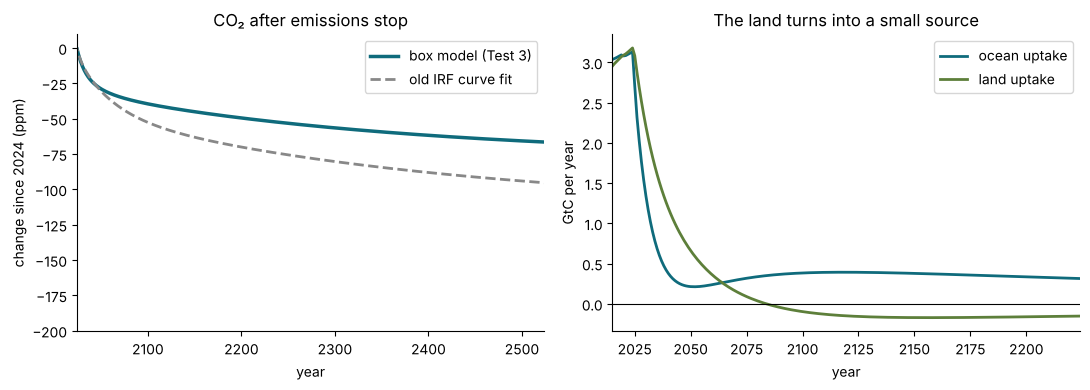

2025: box model   -2.7 ppm   IRF   -2.5 ppm
2034: box model  -18.3 ppm   IRF  -16.8 ppm
2074: box model  -35.4 ppm   IRF  -43.7 ppm
2124: box model  -42.4 ppm   IRF  -58.4 ppm
2524: box model  -66.6 ppm   IRF  -95.4 ppm


In [19]:
res, ys, rs = stop_today(feedback=True)
res0, _, rs0 = stop_today(feedback=False)
show = pd.DataFrame({"with feedback": res, "no feedback": res0}).T.drop(columns=["year excess above 1850 halves"])
display(show)
p = rs["ppm"][:, 0]; i24 = np.where(ys == 2024)[0][0]
# the old curve fit, for comparison: Joos IRF convolution of the same emissions
a = [0.2173, 0.2240, 0.2824, 0.2763]; tau = [394.4, 36.54, 4.304]
irf = lambda t: a[0] + sum(a[i + 1] * np.exp(-t / tau[i]) for i in range(3))
Ef, El, yy = scenario_emissions("stop", end=2524); E = Ef + El
C_irf = START + np.convolve(E, irf(np.arange(len(E)) + 0.5))[:len(E)] / GTC_PER_PPM
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(ys, p - p[i24], color="#0f6b7c", lw=2.5, label="box model (Test 3)")
axs[0].plot(yy, C_irf - C_irf[i24], color="#888", lw=2, ls="--", label="old IRF curve fit")
axs[0].set(xlim=(2024, 2524), xlabel="year", ylabel="change since 2024 (ppm)", title="CO₂ after emissions stop"); axs[0].legend()
axs[1].plot(ys, rs["ocean"][:, 0], color="#0f6b7c", lw=2, label="ocean uptake")
axs[1].plot(ys, rs["land"][:, 0], color="#5d7f3a", lw=2, label="land uptake")
axs[1].axhline(0, color="k", lw=.8)
axs[1].set(xlim=(2015, 2224), xlabel="year", ylabel="GtC per year", title="The land turns into a small source"); axs[1].legend()
plt.tight_layout(); plt.show()
for y in (2025, 2034, 2074, 2124, 2524):
    j = np.where(ys == y)[0][0]
    print(f"{y}: box model {p[j]-p[i24]:+6.1f} ppm   IRF {C_irf[j]-C_irf[i24]:+6.1f} ppm")

**Results.**

- **Fast at first.** CO₂ falls about 2.7 ppm in the first year and about 18 ppm in the first decade, because the ocean and land keep absorbing at nearly today's rate.
- **Then it slows sharply.** It falls only about 42 ppm in 100 years and 67 ppm in 500. About **70% of the rise above 1850 is still there after a century, and over half after 500 years.**
- **Why it slows.** Two mechanisms, which the old curve fit doesn't have:
    1. **Land turns into a source.** As CO₂ falls, the fertilization boost fades. Soils keep releasing the carbon built up over the last century, so land uptake goes slightly negative within a few decades.
    2. **The ocean hits a bottleneck.** The surface and thermocline fill up, and the deep ocean only takes carbon on its roughly 600-year mixing time.
- **Comparison with the IRF.** The old IRF also predicts a decline, since it's a sum of decaying exponentials. Its long-term drop is larger, though, and it can't say *why*, or show the land switching from sink to source.
- **Warming.** With TCRE, warming stops rising once emissions stop: it stays at about 1.3 °C. That matches the IPCC's finding that the zero-emissions commitment is close to zero.